In [ ]:
class_names = {}
with open(CLASSES_FILE, "r", encoding="utf-8") as f:
  for line in f:
    parts = line.strip().split(maxsplit=1)
    if len(parts) == 2:
      idx = int(parts[0]) - 1
      class_names[idx] = parts[1].strip()


def fix_numeric_classes(dataset):
  old_idx_to_class = {v: k for k, v in dataset.class_to_idx.items()}
  numeric_classes = sorted(dataset.classes, key=lambda x: int(x))
  new_class_to_idx = {cls_name: int(cls_name) for cls_name in numeric_classes}

  dataset.classes = numeric_classes
  dataset.class_to_idx = new_class_to_idx
  dataset.samples = [
      (path, int(old_idx_to_class[old_idx]))
      for path, old_idx in dataset.samples
  ]
  dataset.targets = [s[1] for s in dataset.samples]
  return dataset

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = fix_numeric_classes(
    datasets.ImageFolder(DATA_DIR / "train", transform=train_transforms)
)
val_dataset = fix_numeric_classes(
    datasets.ImageFolder(DATA_DIR / "val", transform=eval_transforms)
)
test_dataset = fix_numeric_classes(
    datasets.ImageFolder(DATA_DIR / "test", transform=eval_transforms)
)

train_counts = pd.Series(train_dataset.targets).value_counts().sort_index()

print(f"Imágenes Train: {len(train_dataset):,}")
print(f"Imágenes Val:   {len(val_dataset):,}")
print(f"Imágenes Test:  {len(test_dataset):,}")
print(
    f"Ejemplo verificación -> Clase 72 ({class_names[72]}): {train_counts[72]}"
    " imágenes en Train"
)
print(
    f"Ejemplo verificación -> Clase 101 ({class_names[101]}):"
    f" {train_counts[101]} imágenes en Train"
)

# Crear DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

Imágenes Train: 45,095
Imágenes Val:   7,508
Imágenes Test:  22,619
Ejemplo verificación -> Clase 72 (Erythroneura apicalis): 42 imágenes en Train
Ejemplo verificación -> Clase 101 (Cicadellidae): 3444 imágenes en Train


In [ ]:
def build_resnet152(num_classes=102):
  weights = models.ResNet152_Weights.DEFAULT
  model = models.resnet152(weights=weights)

  in_features = model.fc.in_features
  model.fc = nn.Linear(in_features, num_classes)
  return model


model = build_resnet152(NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
)

scaler = torch.amp.GradScaler("cuda")

print("ResNet-152 cargada en GPU correctamente.")

ResNet-152 cargada en GPU correctamente.


Iniciando entrenamiento hasta 50 épocas (Early Stopping patience=8)...



Época [01/50] (407.7s) | Train Loss: 1.7496 Acc: 55.72% | Val Loss: 1.1840 Acc: 66.90% Macro-F1: 53.79% ★ [MEJOR MODELO GUARDADO]


Época [02/50] (356.8s) | Train Loss: 0.9445 Acc: 72.68% | Val Loss: 1.0895 Acc: 69.99% Macro-F1: 60.71% ★ [MEJOR MODELO GUARDADO]


Época [03/50] (356.4s) | Train Loss: 0.6808 Acc: 79.31% | Val Loss: 1.0559 Acc: 71.31% Macro-F1: 62.41% ★ [MEJOR MODELO GUARDADO]


Época [04/50] (354.9s) | Train Loss: 0.5042 Acc: 84.21% | Val Loss: 1.0592 Acc: 71.46% Macro-F1: 63.70% ★ [MEJOR MODELO GUARDADO]


...

Época [24/50] (352.4s) | Train Loss: 0.0304 Acc: 99.18% | Val Loss: 1.7073 Acc: 73.00% Macro-F1: 66.01% (Sin mejora: 4/8)


Época [25/50] (351.8s) | Train Loss: 0.0258 Acc: 99.24% | Val Loss: 1.8140 Acc: 73.02% Macro-F1: 65.76% (Sin mejora: 5/8)


Época [26/50] (352.6s) | Train Loss: 0.0213 Acc: 99.42% | Val Loss: 1.8142 Acc: 72.56% Macro-F1: 65.69% (Sin mejora: 6/8)


Época [27/50] (351.5s) | Train Loss: 0.0197 Acc: 99.45% | Val Loss: 1.8454 Acc: 72.43% Macro-F1: 66.04% (Sin mejora: 7/8)


Época [28/50] (351.8s) | Train Loss: 0.0160 Acc: 99.58% | Val Loss: 1.8755 Acc: 72.79% Macro-F1: 65.70% (Sin mejora: 8/8)

[Early Stopping] Detenido en la época 28 tras 8 épocas sin mejora en validación.

Entrenamiento finalizado en 165.84 minutos. Mejor Val Macro-F1: 66.37%


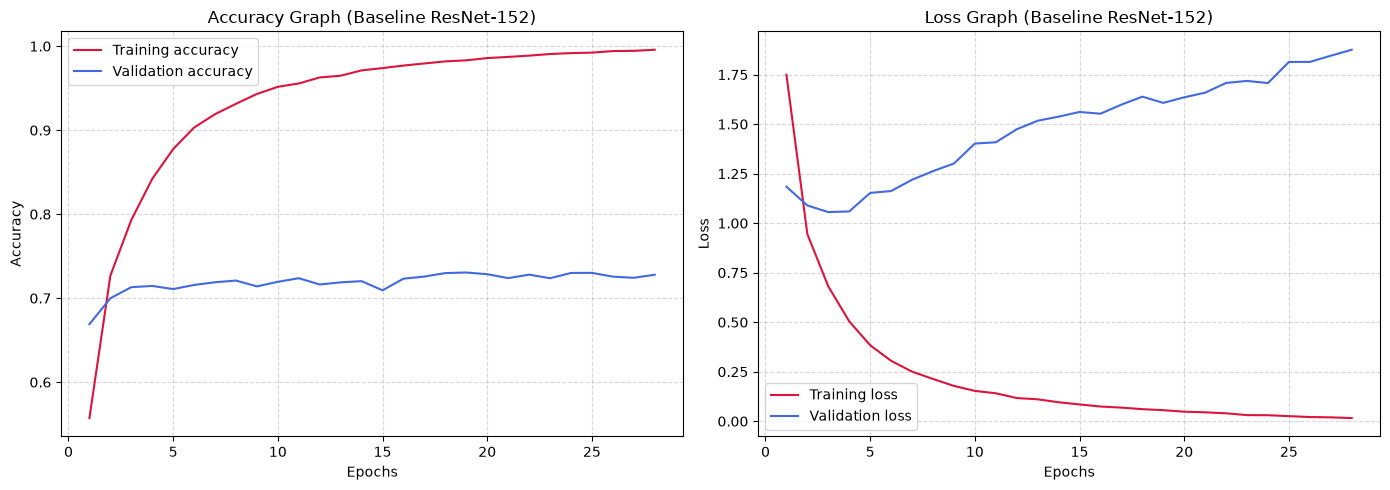

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
  model.train()
  running_loss = 0.0
  all_preds, all_targets = [], []

  pbar = tqdm(loader, desc="Entrenando", leave=False)
  for images, targets in pbar:
    images = images.to(device, non_blocking=True)
    targets = targets.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast("cuda"):
      outputs = model(images)
      loss = criterion(outputs, targets)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    running_loss += loss.item() * images.size(0)
    preds = outputs.argmax(dim=1)
    all_preds.extend(preds.cpu().numpy())
    all_targets.extend(targets.cpu().numpy())

    pbar.set_postfix({"loss": f"{loss.item():.4f}"})

  epoch_loss = running_loss / len(loader.dataset)
  epoch_acc = accuracy_score(all_targets, all_preds)
  epoch_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
  return epoch_loss, epoch_acc, epoch_f1


@torch.no_grad()
def evaluate(model, loader, criterion, device, desc="Validando"):
  model.eval()
  running_loss = 0.0
  all_preds, all_targets = [], []

  pbar = tqdm(loader, desc=desc, leave=False)
  for images, targets in pbar:
    images = images.to(device, non_blocking=True)
    targets = targets.to(device, non_blocking=True)

    with torch.amp.autocast("cuda"):
      outputs = model(images)
      loss = criterion(outputs, targets)

    running_loss += loss.item() * images.size(0)
    preds = outputs.argmax(dim=1)
    all_preds.extend(preds.cpu().numpy())
    all_targets.extend(targets.cpu().numpy())

  epoch_loss = running_loss / len(loader.dataset)
  epoch_acc = accuracy_score(all_targets, all_preds)
  epoch_bal_acc = balanced_accuracy_score(all_targets, all_preds)
  epoch_f1_macro = f1_score(
      all_targets, all_preds, average="macro", zero_division=0
  )
  epoch_f1_weighted = f1_score(
      all_targets, all_preds, average="weighted", zero_division=0
  )

  return (
      epoch_loss,
      epoch_acc,
      epoch_bal_acc,
      epoch_f1_macro,
      epoch_f1_weighted,
      np.array(all_targets),
      np.array(all_preds),
  )


# Entrenamiento principal con Early Stopping
history = []
best_val_f1 = 0.0
epochs_no_improve = 0
best_model_path = OUTPUT_DIR / "best_resnet152_baseline.pth"

print(
    f"Iniciando entrenamiento hasta {NUM_EPOCHS} épocas (Early Stopping"
    f" patience={PATIENCE})...\n"
)
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
  t0 = time.time()

  train_loss, train_acc, train_f1 = train_one_epoch(
      model, train_loader, criterion, optimizer, scaler, device
  )
  val_loss, val_acc, val_bal_acc, val_f1_macro, val_f1_weighted, _, _ = (
      evaluate(model, val_loader, criterion, device)
  )

  scheduler.step()
  elapsed = time.time() - t0

  # Guardar registro de la época
  epoch_log = {
      "epoch": epoch,
      "train_loss": train_loss,
      "train_acc": train_acc,
      "train_f1_macro": train_f1,
      "val_loss": val_loss,
      "val_acc": val_acc,
      "val_balanced_acc": val_bal_acc,
      "val_f1_macro": val_f1_macro,
      "val_f1_weighted": val_f1_weighted,
      "lr": optimizer.param_groups[0]["lr"],
      "time_sec": elapsed,
  }
  history.append(epoch_log)
  df_hist = pd.DataFrame(history)
  df_hist.to_csv(OUTPUT_DIR / "training_history_baseline.csv", index=False)

  # Verificar mejora en Macro F1-Score
  saved_flag = ""
  if val_f1_macro > best_val_f1:
    best_val_f1 = val_f1_macro
    epochs_no_improve = 0
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_f1_macro": best_val_f1,
        },
        best_model_path,
    )
    saved_flag = " ★ [MEJOR MODELO GUARDADO]"
  else:
    epochs_no_improve += 1
    saved_flag = f" (Sin mejora: {epochs_no_improve}/{PATIENCE})"

  print(
      f"Época [{epoch:02d}/{NUM_EPOCHS:02d}] ({elapsed:.1f}s) | "
      f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
      f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}% Macro-F1:"
      f" {val_f1_macro*100:.2f}%{saved_flag}"
  )

  if epochs_no_improve >= PATIENCE:
    print(
        f"\n[Early Stopping] Detenido en la época {epoch} tras"
        f" {PATIENCE} épocas sin mejora en validación."
    )
    break

total_time = (time.time() - start_time) / 60
print(
    f"\nEntrenamiento finalizado en {total_time:.2f} minutos. Mejor Val"
    f" Macro-F1: {best_val_f1*100:.2f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Accuracy (Equivalente a Fig. 18)
axes[0].plot(
    df_hist["epoch"],
    df_hist["train_acc"],
    label="Training accuracy",
    color="crimson",
)
axes[0].plot(
    df_hist["epoch"],
    df_hist["val_acc"],
    label="Validation accuracy",
    color="royalblue",
)
axes[0].set_title("Accuracy Graph (Baseline ResNet-152)")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Gráfica 2: Loss (Equivalente a Fig. 19)
axes[1].plot(
    df_hist["epoch"],
    df_hist["train_loss"],
    label="Training loss",
    color="crimson",
)
axes[1].plot(
    df_hist["epoch"],
    df_hist["val_loss"],
    label="Validation loss",
    color="royalblue",
)
axes[1].set_title("Loss Graph (Baseline ResNet-152)")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "accuracy_and_loss_curves_baseline.png", dpi=300)
plt.show()

Evaluando el mejor modelo (Época 20) sobre el conjunto de TEST...



RESULTADOS BASELINE (RESNET-152 SIN BALANCEAR) - CONJUNTO DE TEST
Overall Accuracy   : 72.48%
Balanced Accuracy  : 64.34%
Macro F1-Score     : 65.27%
Weighted F1-Score  : 72.18%

--- IMPACTO DEL DESBALANCE EN LA COLA LARGA ---
Promedio de las 15 clases MÁS MINORITARIAS (42 a 106 fotos en train):
  -> Recall Promedio : 52.44% | F1 Promedio: 57.34%
Promedio de las 15 clases MÁS MAYORITARIAS (669 a 3,444 fotos en train):
  -> Recall Promedio : 80.80% | F1 Promedio: 79.60%

Detalle de las 10 clases con MENOS datos en Train:


,class_id,pest_name,train_images,test_images,recall,f1_score
72,72,Erythroneura apicalis,42,22,0.500000,0.594595
80,80,Parlatoria zizyphus Lucus,44,23,0.652174,0.731707
61,61,Brevipoalpus lewisi McGregor,47,24,0.833333,0.833333
63,63,Polyphagotars onemus latus,50,26,0.384615,0.434783
98,98,Mango flat beak leafhopper,55,28,0.357143,0.487805
81,81,Nipaecoccus vastalor,59,30,0.333333,0.425532
36,36,beet fly,62,32,0.281250,0.315789
35,35,cerodonta denticornis,82,42,0.452381,0.463415
65,65,parathrene regalis,84,42,0.761905,0.752941
17,17,white margined moth,88,45,0.488889,0.478261


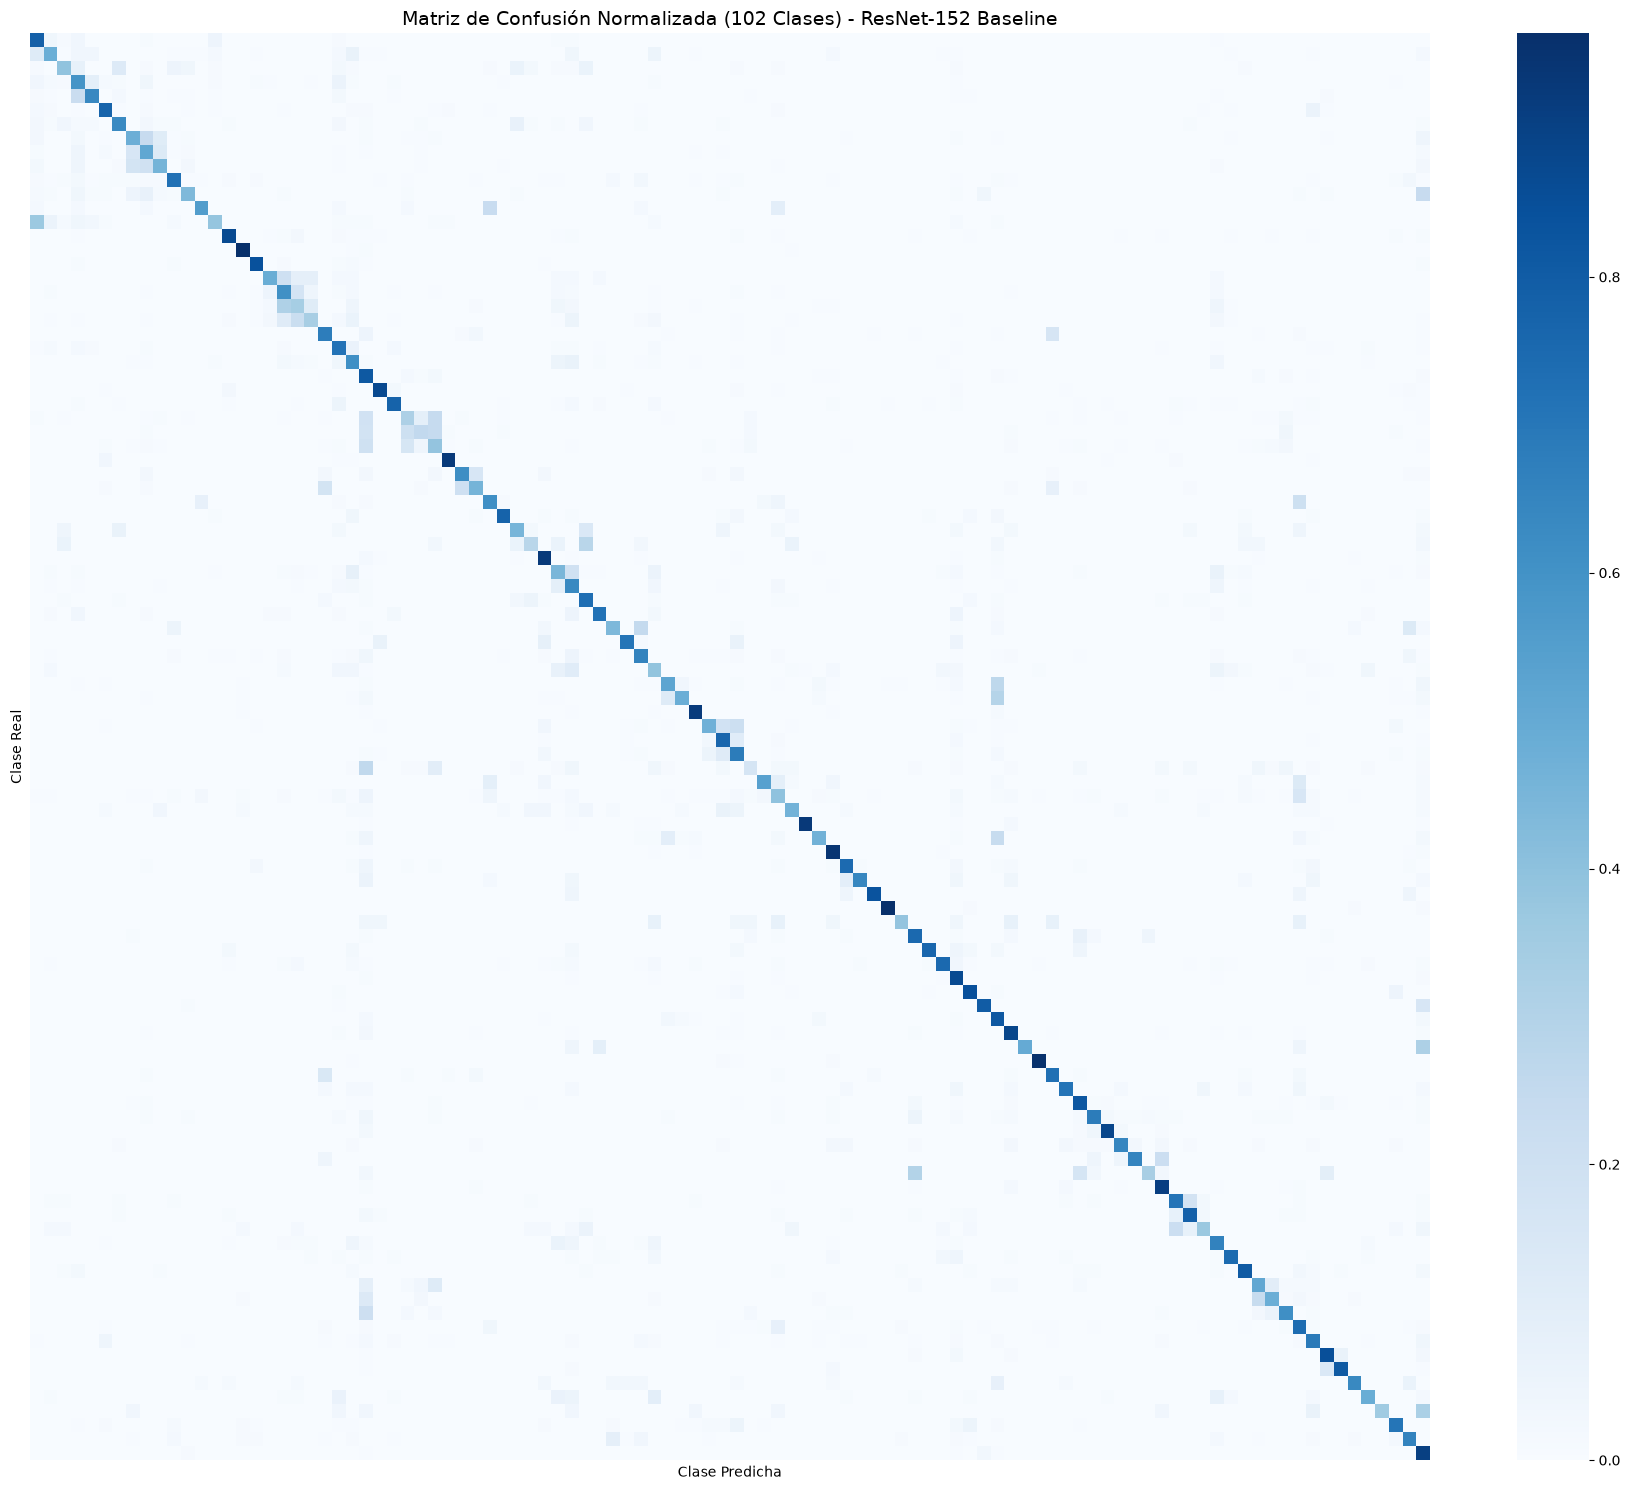

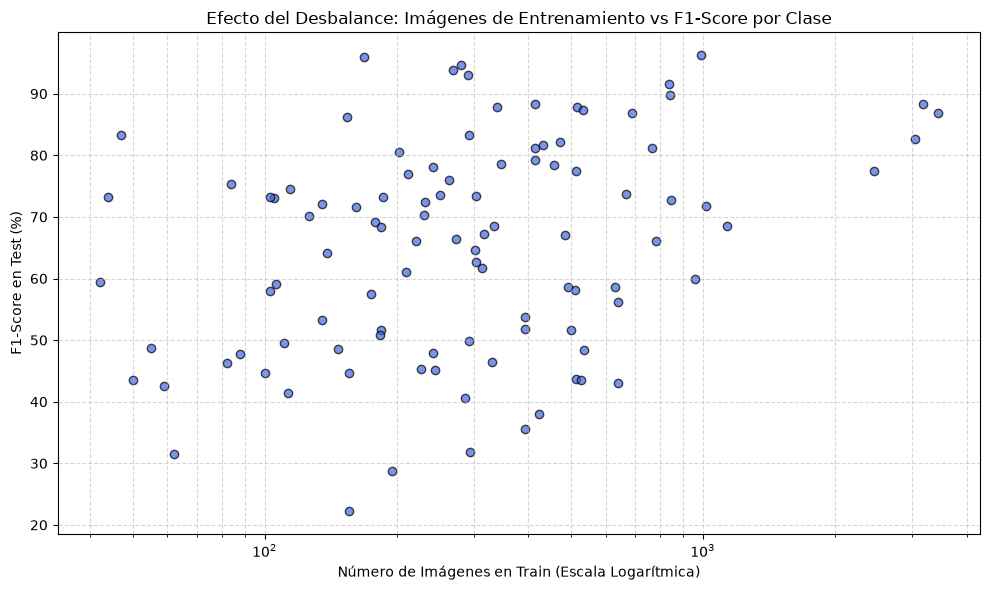

In [ ]:
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
print(
    "Evaluando el mejor modelo (Época"
    f" {checkpoint['epoch']}) sobre el conjunto de TEST..."
)

(
    test_loss,
    test_acc,
    test_bal_acc,
    test_f1_macro,
    test_f1_weighted,
    y_true,
    y_pred,
) = evaluate(
    model, test_loader, criterion, device, desc="Evaluando en Test Set"
)

print("\n" + "=" * 65)
print("RESULTADOS BASELINE (RESNET-152 SIN BALANCEAR) - CONJUNTO DE TEST")
print("=" * 65)
print(f"Overall Accuracy   : {test_acc * 100:.2f}%")
print(f"Balanced Accuracy  : {test_bal_acc * 100:.2f}%")
print(f"Macro F1-Score     : {test_f1_macro * 100:.2f}%")
print(f"Weighted F1-Score  : {test_f1_weighted * 100:.2f}%")
print("=" * 65)

prec, rec, f1_per_class, support_test = precision_recall_fscore_support(
    y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0
)

df_classes = pd.DataFrame({
    "class_id": range(NUM_CLASSES),
    "pest_name": [class_names[i] for i in range(NUM_CLASSES)],
    "train_images": [train_counts[i] for i in range(NUM_CLASSES)],
    "test_images": support_test,
    "precision": prec,
    "recall": rec,
    "f1_score": f1_per_class,
})

df_classes_sorted = df_classes.sort_values(by="train_images", ascending=True)
df_classes_sorted.to_csv(
    OUTPUT_DIR / "baseline_per_class_metrics.csv", index=False
)

bottom_15 = df_classes_sorted.head(15)
top_15 = df_classes_sorted.tail(15)

print("\n--- IMPACTO DEL DESBALANCE EN LA COLA LARGA ---")
print(
    "Promedio de las 15 clases MÁS MINORITARIAS (42 a"
    f" {bottom_15['train_images'].max()} fotos en train):"
)
print(
    f"  -> Recall Promedio : {bottom_15['recall'].mean()*100:.2f}% | F1"
    f" Promedio: {bottom_15['f1_score'].mean()*100:.2f}%"
)
print(
    "Promedio de las 15 clases MÁS MAYORITARIAS"
    f" ({top_15['train_images'].min()} a 3,444 fotos en train):"
)
print(
    f"  -> Recall Promedio : {top_15['recall'].mean()*100:.2f}% | F1 Promedio:"
    f" {top_15['f1_score'].mean()*100:.2f}%"
)

print("\nDetalle de las 10 clases con MENOS datos en Train:")
display(
    bottom_15.head(10)[[
        "class_id",
        "pest_name",
        "train_images",
        "test_images",
        "recall",
        "f1_score",
    ]]
)

summary = {
    "model": "ResNet-152 (Baseline Unbalanced)",
    "resolution": f"{IMG_SIZE}x{IMG_SIZE}",
    "best_epoch": int(checkpoint["epoch"]),
    "test_overall_accuracy": float(test_acc),
    "test_balanced_accuracy": float(test_bal_acc),
    "test_macro_f1": float(test_f1_macro),
    "test_weighted_f1": float(test_f1_weighted),
    "bottom_15_minority_mean_recall": float(bottom_15["recall"].mean()),
    "bottom_15_minority_mean_f1": float(bottom_15["f1_score"].mean()),
    "top_15_majority_mean_recall": float(top_15["recall"].mean()),
    "top_15_majority_mean_f1": float(top_15["f1_score"].mean()),
}
with open(
    OUTPUT_DIR / "baseline_metrics_summary.json", "w", encoding="utf-8"
) as f:
  json.dump(summary, f, indent=4, ensure_ascii=False)

cm = confusion_matrix(
    y_true, y_pred, labels=range(NUM_CLASSES), normalize="true"
)
plt.figure(figsize=(18, 15))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title(
    "Matriz de Confusión Normalizada (102 Clases) - ResNet-152 Baseline",
    fontsize=14,
)
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_baseline.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(
    df_classes["train_images"],
    df_classes["f1_score"] * 100,
    alpha=0.7,
    c="royalblue",
    edgecolors="k",
)
plt.xscale("log")
plt.xlabel("Número de Imágenes en Train (Escala Logarítmica)")
plt.ylabel("F1-Score en Test (%)")
plt.title(
    "Efecto del Desbalance: Imágenes de Entrenamiento vs F1-Score por Clase"
)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "imbalance_vs_f1_baseline.png", dpi=300)
plt.show()